<center>
<img src="../images/fscampus_small2.png" width="1200"/>
</center>

<center>

# Investments

***Finance 2 - BFIN***

**Dr. Omer Cayirli**

Lecturer in Empirical Finance

omer_cayirli@uncbusiness.net
</center>

---

## Lecture 09

---


### Outline

*   Derivatives I
    *   Introduction to derivatives
    
    *   Futures & Forwards
    
    *   Swap Contracts

---



### Derivatives: Purpose and uses

- Derivative: value linked to an underlying asset, rate, index, or event.
- Main forms: forwards, futures, options, and swaps.

- Uses
    - Hedging: offset an existing or planned exposure.
    - Speculation: take exposure without an offsetting position.
    - Arbitrage: exploit inconsistent prices through offsetting trades.
    - Transform an investment's or liability's exposure without replacing it.

- Underlyings: equities, interest rates, currencies, commodities, and credit risk.

---


### Forward Contracts

- Forward: OTC agreement fixing the quantity, delivery price, and future delivery date.
- Both parties obligated to perform.

| Position | Obligation at maturity | Payoff per unit |
|---|---|---:|
| Long | Buy the underlying | $S_T-F$ |
| Short | Sell the underlying | $F-S_T$ |

$S_T$: terminal spot price; $F$: agreed delivery price.

- At inception: set $F$ for zero contract value; no initial premium.
- After inception: contract value changes with market conditions.
- Collateral may still be required.

---


### Forward Contracts: Choosing a hedge

| Exposure | Hedge | Adverse currency move |
|---|---|---|
| Alpha must pay JPY 500 million in 3 months | Buy JPY forward | JPY appreciation |
| Beta will receive EUR 5 million in 6 months | Sell EUR forward | EUR depreciation |

Exchange-rate quote: home currency per unit of foreign currency.

- Match the hedge's amount and maturity to the exposure.
- Evaluate hedge and underlying together: a forward loss can offset an underlying gain.

---


### Forward Pricing: Replication

- Assumptions: no income, storage costs, or transaction costs.
- $r_f$: fixed annual effective risk-free rate.

Replication: long forward + risk-free bond paying $F$ at maturity.

| Position | Cost today | Payoff at $T$ |
|---|---:|---:|
| Buy the asset | $S_0$ | $S_T$ |
| Long forward | $0$ | $S_T-F$ |
| Buy the bond | $F/(1+r_f)^T$ | $F$ |
| Forward + bond | $F/(1+r_f)^T$ | $S_T$ |

Identical payoffs imply identical costs:

$$S_0=\frac{F}{(1+r_f)^T}
\quad\Rightarrow\quad F=S_0(1+r_f)^T.$$

- Example: $S_0=50$, $r_f=5\%$, $T=1$; forward price $52.50$.
- Synthetic position: cost $50$ today; payoff $S_T$ at maturity.

---


In [3]:
import numpy as np
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display, Math


def plot_replication(S0, rf_pct, T):
    rf = rf_pct / 100
    F = S0 * (1 + rf)**T
    bond_cost = F / (1 + rf)**T

    display(Math(
        rf"F=S_0(1+r_f)^T={S0:.2f}(1+{rf:.3f})^{{{T}}}={F:.2f}"
    ))
    display(Math(
        (r"\underbrace{0}_{\text{Long forward}}"
         r"+\underbrace{\frac{%.2f}{(1+%.3f)^{%d}}}_{\text{Bond: }PV(F)}"
         r"=%.2f=S_0") % (F, rf, T, bond_cost)
    ))

    # Include the forward break-even even when carrying costs are large.
    st_max = max(1.5 * S0, 1.15 * F)
    ST = np.unique(np.r_[np.linspace(0, st_max, 250), S0, F])
    forward_payoff = ST - F
    bond_payoff = np.full_like(ST, F)
    synthetic_payoff = forward_payoff + bond_payoff

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.5),
                                 layout="constrained")

    ax1.plot(ST, forward_payoff, "--", color="#0072B2", linewidth=2,
             label=r"Long forward: $S_T-F$")
    ax1.plot(ST, bond_payoff, ":", color="#009E73", linewidth=2.5,
             label=r"Bond: $F$")
    ax1.plot(ST, synthetic_payoff, color="#222222", linewidth=2.5,
             label=r"Forward + bond: $S_T$")
    sample = np.linspace(0, st_max, 9)
    ax1.scatter(sample, sample, color="#D55E00", marker="x", s=45,
                zorder=4, label=r"Asset: $S_T$")
    ax1.axhline(0, color="#666666", linewidth=0.8)
    ax1.axvline(F, color="#666666", linestyle="--", linewidth=0.9)
    ax1.scatter([F], [0], color="#0072B2", s=40, zorder=5)
    ax1.annotate(f"F = {F:.2f}", xy=(F, 0), xytext=(-7, 12),
                 textcoords="offset points", ha="right", fontsize=10)
    ax1.set_xlim(0, st_max)
    ax1.set_ylim(-1.12 * F, 1.4 * st_max)
    ax1.set_title(f"Payoffs at maturity: T = {T} year(s)")
    ax1.set_xlabel(r"Terminal asset price $S_T$ (USD)")
    ax1.set_ylabel("Payoff (USD)")
    ax1.legend(loc="upper left", frameon=False, fontsize=9)

    # This is the deterministic loan balance, not the risky asset's price.
    time = np.linspace(0, T, 150)
    financing_balance = S0 * (1 + rf)**time
    ax2.plot(time, financing_balance, color="#7B3294", linewidth=2.5)
    ax2.scatter([0, T], [S0, F], color="#7B3294", s=45, zorder=4)
    pad = max(0.12 * (F - S0), 0.05 * S0)
    ax2.set_xlim(-0.05 * T, 1.05 * T)
    ax2.set_ylim(S0 - 2 * pad, F + 3 * pad)
    ax2.text(0.03, 0.96, f"Loan: USD {S0:.2f} at {rf_pct:.1f}% annually",
             transform=ax2.transAxes, va="top", fontsize=10)
    ax2.annotate(f"S0 = {S0:.2f}", xy=(0, S0), xytext=(7, -18),
                 textcoords="offset points", ha="left", fontsize=10)
    ax2.annotate(f"Repayment = F = {F:.2f}", xy=(T, F), xytext=(-7, 10),
                 textcoords="offset points", ha="right", fontsize=10)
    ax2.set_title("Financing the spot purchase")
    ax2.set_xlabel("Time (years)")
    ax2.set_ylabel("Loan balance (USD)")

    for ax in (ax1, ax2):
        ax.spines[["top", "right"]].set_visible(False)
        ax.grid(True, linestyle=":", alpha=0.3)
        ax.set_axisbelow(True)
    plt.show()


style = {"description_width": "initial"}
s0_slider = widgets.FloatSlider(
    value=50, min=10, max=100, step=1, description="Spot price (USD):",
    style=style, continuous_update=False)
rf_slider = widgets.FloatSlider(
    value=5, min=0, max=15, step=0.5, description="Annual effective rate (%):",
    style=style, continuous_update=False)
t_slider = widgets.IntSlider(
    value=1, min=1, max=5, step=1, description="Maturity (years):",
    style=style, continuous_update=False)

output = widgets.interactive_output(
    plot_replication, {"S0": s0_slider, "rf_pct": rf_slider, "T": t_slider})
ui = widgets.VBox([
    widgets.HBox([s0_slider, rf_slider, t_slider],
                 layout=widgets.Layout(flex_flow="row wrap")),
    output
])
display(ui)


### Forward Pricing: Arbitrage

- Kappa: spot price USD 80; one-year forward price USD 81 per share; no dividends.
- Risk-free rate: 5% annual effective.

- Borrowing, lending, and short selling permitted; short-sale proceeds fully investable.
- Ignore transaction costs, stock-borrowing fees, and collateral requirements.

a. What is the no-arbitrage forward price?

b. Does the quoted price permit arbitrage? For 100 shares, specify the trades and show the initial cash flow and terminal profit.

---

### Forward Pricing: Arbitrage

a. No-arbitrage price:

$$F^*=80(1.05)=84.$$

b. Quoted price below $F^*$:

- Short the shares; invest the proceeds; buy the shares forward.

| Trade | Cash flow today (USD) | At maturity |
|---|---:|---|
| Short 100 shares | +8,000 | Return the 100 shares acquired below |
| Invest the proceeds at 5% | -8,000 | Receive USD 8,400 |
| Buy 100 shares forward at USD 81 | 0 | Pay USD 8,100 and receive 100 shares |
| Net | 0 | USD 300 profit; all positions closed |

Terminal-value check:

$$\Pi_T=-100S_T+100(S_T-81)+8{,}000(1.05)=300.$$

- The $S_T$ terms cancel: USD 300 profit regardless of the terminal share price.

---


### Futures Contracts and Margin

- Futures: exchange-traded; standardized quantity, maturity, and settlement or delivery terms.

- Daily marking to market: gains and losses credited or debited to margin.
- Initial margin: collateral posted by both sides, not the asset's purchase price.
- Margin-call convention: balance below maintenance triggers a deposit restoring initial margin.

Daily settlement for $n$ contracts of size $Q$:

$$\text{Long P\&L}=nQ(F_t-F_{t-1}),\qquad
\text{Short P\&L}=nQ(F_{t-1}-F_t).$$

- Hedging price risk can still create interim cash needs through margin calls.

---


### Futures Contracts: Marking to market

- Kappa: short three oil futures at USD 80.00 per barrel; 1,000 barrels per contract.
- Total margin: USD 15,000 initial; USD 10,500 maintenance.

- Settlement prices, days 1-4: USD 81.00, 81.50, 82.00, 79.50 per barrel.
- Below maintenance: immediate deposit restoring initial margin.
- No withdrawals, interest, or fees; close at the day-4 settlement price.

a. Track daily P&L, additional deposits, and the closing margin balance.

b. Calculate total trading profit and reconcile it with the final account balance.

---

### Futures Contracts: Marking to market

Short-position settlement:

$$\text{Daily P\&L}=3(1{,}000)(F_{t-1}-F_t).$$

Account amounts: USD.

| Day | Futures price (USD/barrel) | Daily P&L | Balance before deposit | Additional deposit | Closing balance |
|---|---:|---:|---:|---:|---:|
| 0 | 80.00 | N/A | N/A | 0 | 15,000 |
| 1 | 81.00 | -3,000 | 12,000 | 0 | 12,000 |
| 2 | 81.50 | -1,500 | 10,500 | 0 | 10,500 |
| 3 | 82.00 | -1,500 | 9,000 | 6,000 | 15,000 |
| 4 | 79.50 | +7,500 | 22,500 | 0 | 22,500 |

- Day 2: exactly at maintenance; no call.
- Day 3: deposit $15{,}000-9{,}000=6{,}000$.

Total trading profit:

$$-3{,}000-1{,}500-1{,}500+7{,}500
=3{,}000(80.00-79.50)=1{,}500.$$

Account reconciliation:

$$22{,}500-15{,}000-6{,}000=1{,}500.$$

- Final profit: USD 1,500; interim funding need: USD 6,000.

---


### Futures Contracts: Margin thresholds

- Kappa: short 3,000 barrels at USD 80.00.
- Margin: USD 15,000 initial; USD 10,500 maintenance.

Balance at settlement price $P$, before additional deposits or withdrawals:

$$B(P)=15{,}000+3{,}000(80.00-P).$$

First margin-call threshold:

$$
\begin{aligned}
B(P)&<10{,}500\\
3{,}000(P-80.00)&>15{,}000-10{,}500=4{,}500\\
P&>81.50.
\end{aligned}
$$

- Day 2 at USD 81.50: no call.
- Day 3 at USD 82.00: margin call.

After day 3's USD 6,000 deposit:

$$B(P)=15{,}000+6{,}000+3{,}000(80.00-P).$$

Day 4 at USD 79.50:

$$B(79.50)=21{,}000+1{,}500=22{,}500.$$

If excess margin could be withdrawn while the position remained open:

$$22{,}500-15{,}000=7{,}500.$$

- USD 7,500 = USD 6,000 additional margin funding + USD 1,500 profit.
- Closing the position releases the full USD 22,500 balance.

---


### Forward and Futures Pricing

- Convention: continuously compounded annual rates; $T$ in years.
- Same pricing for forwards and futures when interest rates are deterministic.

| Underlying / carrying cash flow | No-arbitrage price |
|---|---|
| No income or storage costs | $F=S_0e^{rT}$ |
| Known cash income with present value $I$ | $F=(S_0-I)e^{rT}$ |
| Continuous income yield $q$ | $F=S_0e^{(r-q)T}$ |
| Currency, quoted as domestic per foreign unit | $F_{D/F}=S_{0,D/F}e^{(r_D-r_F)T}$ |
| Storage costs with present value $U$ | $F=(S_0+U)e^{rT}$ |
| Continuous proportional storage cost $u$ | $F=S_0e^{(r+u)T}$ |
| Net convenience yield $y$ | $F=S_0e^{(r-y)T}$ |

- Cost of carry: reduced by income; increased by financing and storage.
- Convenience yield: noncash benefit of holding physical inventory; $y$ is net of storage costs.
- Storage-only rows assume no income or convenience benefit.
- Assumptions: no transaction costs; required financing and trades feasible.

---


### Pricing Examples

- Convention: continuously compounded annual rates.

| Case | Inputs | Forward / futures price |
|---|---|---|
| Stock index | $S_0=1{,}500$, $r=3\%$, dividend yield $q=1\%$, $T=0.5$ | $1{,}500e^{(0.03-0.01)0.5}=1{,}515.08$ |
| Bond | Full price $S_0=980$; one coupon of $40$ in 3 months; $r=4\%$, $T=0.5$ | $(980-40e^{-0.04(0.25)})e^{0.04(0.5)}=959.40$ |
| Corn | $S_0=5.00$ per bushel; one-year storage cost $0.12$ paid today; $r=5\%$, $T=1$ | $(5.00+0.12)e^{0.05}=5.38$ |

- Bond: subtract the coupon's present value.
- Corn: storage is paid today; no discounting needed.

---


### Swaps: Structure and interest-rate payments

- Swaps: cash-flow exchanges on several dates; forwards: a single future date.
    - Main types: interest-rate, currency, and credit default swaps.
    - Counterparty exposure: reduced through collateral and clearing.

- Fixed-for-floating interest-rate swap
    - Same currency and notional $N$ for both legs; no principal exchange.
    - Payments on the same date normally netted.

$$\text{Fixed payment}=NK\Delta,\qquad
\text{Floating payment}=NL_k\Delta,\qquad
\text{Net receipt to fixed payer}=N(L_k-K)\Delta.$$

$K$: annual fixed rate; $L_k$: annualized floating rate for period $k$; $\Delta$: year fraction.

- Par swap at inception: choose $K$ to equate the present values of both legs.

- USD overnight-indexed swaps: daily SOFR compounded over the payment period.
    - SOFR: overnight borrowing rate secured by Treasury securities.
    - $L_k$: annualized compounded return, known at the period's end.

[SOFR convention: ARRC](https://resources.newyorkfed.org/medialibrary/microsites/arrc/files/2019/Templates_for_Using_SOFR.pdf)

---


### Interest-Rate Swap: Cash flows

- Gamma: pays 4% fixed; receives compounded SOFR from Delta.
- Terms: USD 50 million notional; three years; semiannual payments ($\Delta=0.5$).
- Rates below: hypothetical realized annualized compounded rates.

Cash flows: USD millions, from Gamma's perspective.

| Payment time (years) | $L_k$ for the period just ended | Floating received | Fixed paid | Net receipt |
|---:|---:|---:|---:|---:|
| 0.5 | 4.20% | 1.05 | -1.00 | +0.05 |
| 1.0 | 4.80% | 1.20 | -1.00 | +0.20 |
| 1.5 | 5.40% | 1.35 | -1.00 | +0.35 |
| 2.0 | 4.60% | 1.15 | -1.00 | +0.15 |
| 2.5 | 3.80% | 0.95 | -1.00 | -0.05 |
| 3.0 | 3.20% | 0.80 | -1.00 | -0.20 |

Payment at year 1:

$$\text{Floating}=50(0.048)(0.5)=1.20,\qquad
\text{Fixed}=50(0.04)(0.5)=1.00,$$
$$\text{Net receipt}=1.20-1.00=0.20.$$

---


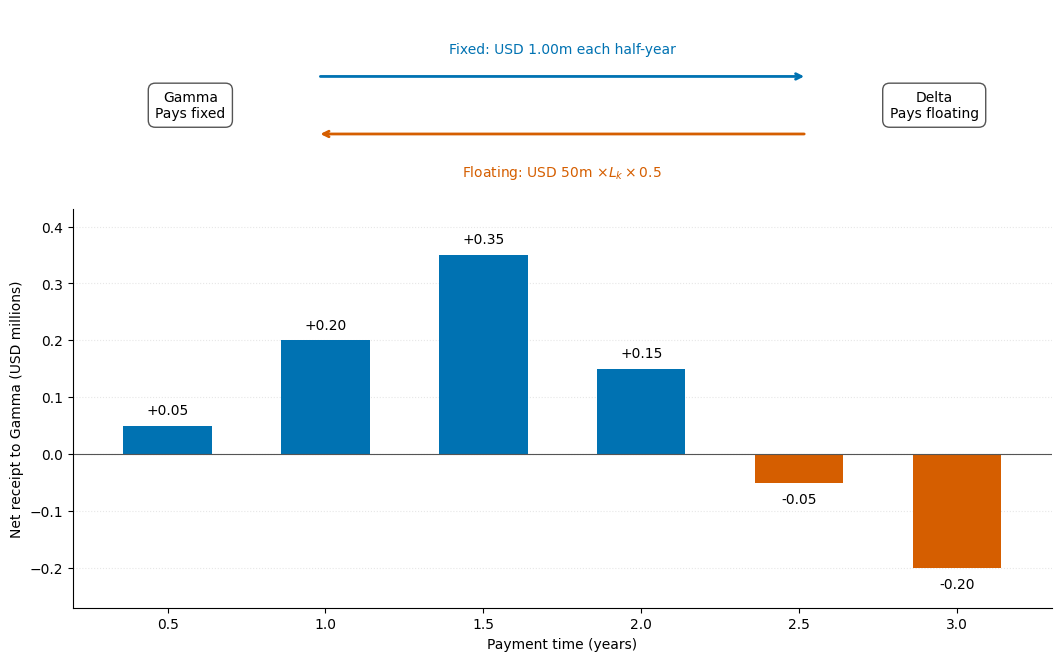

In [4]:
import numpy as np
import matplotlib.pyplot as plt

# Same hypothetical realized rates and terms as the preceding table.
notional = 50_000_000
fixed_rate = 0.04
accrual = 0.5
payment_times = np.arange(1, 7) * accrual
period_rates = np.array([0.042, 0.048, 0.054, 0.046, 0.038, 0.032])

fixed_payments = np.full(period_rates.size, notional * fixed_rate * accrual)
floating_payments = notional * period_rates * accrual
net_receipts = floating_payments - fixed_payments
net_millions = net_receipts / 1_000_000

fig, (structure, cashflows) = plt.subplots(
    2, 1, figsize=(10.5, 6.5), layout="constrained",
    gridspec_kw={"height_ratios": [0.65, 1.35]}
)
structure.axis("off")
structure.set_xlim(0, 1)
structure.set_ylim(0, 1)
box = {"boxstyle": "round,pad=0.5", "fc": "white", "ec": "#555555"}
structure.text(0.12, 0.5, "Gamma\nPays fixed", ha="center", va="center", bbox=box)
structure.text(0.88, 0.5, "Delta\nPays floating", ha="center", va="center", bbox=box)
structure.annotate("", xy=(0.75, 0.65), xytext=(0.25, 0.65),
                   arrowprops={"arrowstyle": "->", "lw": 2, "color": "#0072B2"})
structure.text(0.5, 0.77, "Fixed: USD 1.00m each half-year",
               ha="center", color="#0072B2")
structure.annotate("", xy=(0.25, 0.35), xytext=(0.75, 0.35),
                   arrowprops={"arrowstyle": "->", "lw": 2, "color": "#D55E00"})
structure.text(0.5, 0.13, r"Floating: USD 50m $\times L_k \times 0.5$",
               ha="center", color="#D55E00")

colors = np.where(net_receipts >= 0, "#0072B2", "#D55E00")
cashflows.bar(payment_times, net_millions, width=0.28, color=colors)
cashflows.axhline(0, color="#555555", linewidth=0.8)
for t, amount in zip(payment_times, net_millions):
    cashflows.annotate(
        f"{amount:+.2f}", xy=(t, amount),
        xytext=(0, 6 if amount >= 0 else -7), textcoords="offset points",
        ha="center", va="bottom" if amount >= 0 else "top"
    )
cashflows.set_xticks(payment_times)
cashflows.set_xlim(0.2, 3.3)
cashflows.set_ylim(-0.27, 0.43)
cashflows.set_xlabel("Payment time (years)")
cashflows.set_ylabel("Net receipt to Gamma (USD millions)")
cashflows.spines[["top", "right"]].set_visible(False)
cashflows.grid(axis="y", linestyle=":", alpha=0.3)
cashflows.set_axisbelow(True)
plt.show()


### Interest-Rate Swaps: Changing an exposure

- Alpha pays Beta 4% fixed and receives floating rate $L$.
- Matching required: notional, accrual period, payment dates, and floating-rate convention.

Borrowings: annual payment rates

| Cash flow | Alpha | Beta |
|---|---:|---:|
| Existing loan | $L+0.2\%$ | $4.5\%$ |
| Pay under swap | $4.0\%$ | $L$ |
| Receive under swap | $-L$ | $-4.0\%$ |
| Net cost | $4.2\%$ | $L+0.5\%$ |

Investments: a separate use of the same swap

| Cash flow | Alpha | Beta |
|---|---:|---:|
| Existing investment income | $3.8\%$ | $L-0.1\%$ |
| Pay under swap | $-4.0\%$ | $-L$ |
| Receive under swap | $L$ | $4.0\%$ |
| Net income | $L-0.2\%$ | $3.9\%$ |

- Rate exposure changes; the underlying loan or investment and its credit risk remain.

---


### Currency Swaps

- Fixed-for-fixed currency swap: interest payments in two currencies.
- Principal: usually exchanged at inception and returned at maturity.

- Delta and Epsilon: five-year swap with annual payments.
    - Delta pays 4% on EUR 18 million; receives 5% on USD 20 million.

Delta's cash flows, in millions; positive = receipt.

| Time | USD cash flow | EUR cash flow |
|---|---:|---:|
| Inception: exchange principal | -20.00 | +18.00 |
| End of each year 1-4: interest | +1.00 | -0.72 |
| End of year 5: interest + principal | +21.00 | -18.72 |

$$\text{Annual USD receipt}=20(0.05)=1.00,\qquad
\text{Annual EUR payment}=18(0.04)=0.72.$$

- Final payment: last interest payment plus the reverse principal exchange.
- Convert to a common currency before adding USD and EUR amounts.

---


### Credit Default Swaps

- CDS: transfer of a reference entity's credit-event risk.
- Contract terms: covered events (e.g., failure to pay) and eligible obligations.

- Protection buyer: pays premiums while the contract is active.
- Protection seller: compensates the buyer after a covered credit event.

| Settlement | Exchange |
|---|---|
| Physical | Buyer delivers eligible debt; seller pays its contractual par amount |
| Cash | Seller pays $N(1-\mathcal R)$, where $\mathcal R$ is the settlement recovery fraction, often determined by auction |

Example: USD 10 million notional; 40% recovery.

$$\text{Cash settlement}=10(1-0.40)=\text{USD }6\text{ million}.$$

- USD 6 million: protection payment before deducting premiums paid.
- Counterparty risk: the seller must be able to meet the obligation.

[Settlement reference: ISDA](https://www.isda.org/traditional-protocol/small-bang-protocol/)

---


### Sovereign CDS: Interpreting a spread

Historical comparison: 10-year sovereign CDS spreads, July 2023.

| Reference sovereign | Annual spread | Basis points |
|---|---:|---:|
| Germany | 0.22% | 22 |
| United States | 0.43% | 43 |
| Morocco | 1.95% | 195 |
| Brazil | 2.88% | 288 |

- Premium example: 288 bp on USD 10 million.
- Assume no upfront payment, four equal accrual periods, and no credit event during the year.

$$\text{Annual premium}=0.0288(10{,}000{,}000)=\text{USD }288{,}000,$$
$$\text{Quarterly premium}=288{,}000/4=\text{USD }72{,}000.$$

- Standard contracts may use a fixed coupon plus an upfront payment.

- Spread: price of protection, not a default probability.
    - Also reflects recovery, risk compensation, and liquidity.

Source: [Damodaran, July 2023 data](https://pages.stern.nyu.edu/~adamodar/pc/blog/Ratings%26CDS2023.xlsx); [tenor and context, 2023 paper](https://ssrn.com/abstract=4509578).

---


### Question 1

- In a copper market, all producers, including Kappa, and cable manufacturers, including Lambda, hedge their planned sales and purchases for the next six months using exchange-traded futures.
- Assume exact matches in quantity, timing, and price exposure between the hedges and the physical transactions.

Discuss:

1. Price Discovery: Who determines spot copper prices once these firms are fully hedged? Must the futures market become the main driver of spot prices?

2. The Speculator's Role: Can speculators still provide economic value? Does the zero-sum nature of futures payoffs rule out a benefit from trading or a risk premium?

3. Systemic Risk: Does full hedging necessarily concentrate commodity-price risk in clearinghouses and increase systemic risk?

---


### Question 2

A nine-month long forward contract on one non-dividend-paying Theta share is entered into at the fair forward price. The share price is $84 and the continuously compounded risk-free rate is 4% per annum.

1. What is the initial forward price?

2. Four months later, the share price is $82 and the risk-free rate is unchanged. What is the value of the existing long forward contract?

---

### Question 3

Kappa enters into a forward contract to buy a four-year, default-free zero-coupon bond that will be issued in three years.

- Face value: $2,000.
- Three-year spot rate: 3%; seven-year spot rate: 5%, both compounded annually.

What is the forward price?

---

### Question 4

Consider a six-month forward contract on the Sigma stock index, currently at 2,400.

- The continuous dividend yield is 1.5% per annum for the first two months and 3% per annum for the remaining four months. These yields are known with certainty.
- The continuously compounded risk-free rate is 5% per annum throughout.

What is the forward price?

---

### Question 5

Kappa observes the following exchange rates and interest rate:

- Spot GBP/USD rate: 1.2500 USD per GBP.
- One-year forward rate: 1.2300 USD per GBP.
- One-year USD risk-free rate: 4% per annum, continuously compounded.

Ignore transaction costs; borrowing and lending rates are equal within each currency.

Estimate the one-year GBP risk-free rate, expressed with continuous compounding.

---

### Question 6

Delta observes a spot exchange rate of 1.1600 USD per EUR. The continuously compounded risk-free rates are 4.5% per annum in USD and 2.5% in EUR.

- (a) If the six-month forward rate is 1.1900 USD per EUR, what arbitrage strategy is possible?
- (b) If the six-month forward rate is instead 1.1500 USD per EUR, what arbitrage strategy is possible?

For each case, show the profit in USD using an initial borrowing with a spot value of USD 400,000. Ignore transaction costs; borrowing and lending rates are equal within each currency.

---

### Question 7

Assume deterministic interest rates and no transaction costs.

- (a) Index futures: A six-month futures contract on the Sigma index trades at 4,200. The risk-free rate is 3% per annum, continuously compounded, and the continuous dividend yield is 1.2% per annum. What is the no-arbitrage spot index level?

- (b) Bond futures: Calculate the six-month futures price for delivery of a specified bond.
  - Full (dirty) spot price: USD 98.50 per USD 100 face value.
  - Risk-free rate: 6% effective annual rate.
  - The only coupon before delivery is USD 2.50 per USD 100 face value, paid in two months.

- (c) Convenience yield: Oil trades at USD 74.00 per barrel; the six-month futures price is USD 72.80. The continuously compounded risk-free rate is 3.5% per annum. What is the implied net annual convenience yield $y$ (convenience yield less storage costs), expressed with continuous compounding?

---

### Question 8

All interest rates are effective annual rates. Ignore transaction costs other than the stated storage cost.

1. Commodity forward: Kappa observes a spot price of USD 1,250 per unit and a one-year forward price of USD 1,375.
   - Storage costs 2% of today's spot price, payable at the end of the year. There is no income or convenience yield.
   - (a) What risk-free rate is implied by these prices?
   - (b) If the actual risk-free borrowing and lending rate is 5%, what arbitrage strategy is possible, and what is the profit per unit?

2. Currency forward: The spot exchange rate is 0.0550 USD per MXN; the one-year forward rate is 0.0565 USD per MXN. The USD risk-free rate is 5%.
   - What is the implied MXN risk-free rate?

---

### Question 9

Lambda pays 4.2% fixed and receives floating from Mu under a one-year swap.

- Notional: USD 24 million; quarterly payments with $\Delta=0.25$.
- The annualized compounded floating rates realized over the four quarters are 3.6%, 4.8%, 4.1%, and 5.1%.

(a) Calculate both legs and the net settlement each quarter. Identify who pays whom.

(b) What is Lambda's total net receipt over the year, without discounting? What principal payment is due under the swap at maturity?

---

### Question 10

Eta and Theta can enter a swap exchanging 4.4% fixed for floating rate $L$.

- All rates are annual payment rates.
- Within each case, the loan or investment and swap have matching notionals, maturities, payment dates, accrual periods, and floating-rate conventions. Ignore fees.

Consider the two cases independently:

| Case | Eta's existing position | Eta wants | Theta's existing position | Theta wants |
|:---|:---|:---|:---|:---|
| Borrowing | Pays $L+0.7\%$ | Fixed cost | Pays 5.4% | Floating cost |
| Investment | Receives 4.0% | Floating income | Receives $L-0.3\%$ | Fixed income |

(a) For each case, choose each party's swap direction and calculate its net annual borrowing cost or investment income.

(b) In the investment case, does the swap remove the credit risk of the underlying investments? Explain briefly.

---

### Question 11

Epsilon needs EUR 10 million for three years. It borrows USD 12 million at 5% annual interest, with principal repaid at maturity, and enters a fixed-for-fixed currency swap with Zeta.

- Spot exchange rate at inception: 1.20 USD per EUR.
- Swap notionals: USD 12 million and EUR 10 million.
- Epsilon receives 5% on the USD notional and pays 3.6% on the EUR notional, annually.
- The principals are exchanged at inception and reversed at maturity. Ignore fees.

(a) Show Epsilon's swap cash flows in each currency at inception, in years 1-2, and at maturity.

(b) Combine the swap with the USD loan. What are Epsilon's net cash flows and effective annual EUR borrowing cost?

(c) If the loan instead charges 5.6%, with all swap terms unchanged, is the funding entirely converted into fixed EUR payments? Quantify any remaining exposure.

---

### What is next?

*   Derivatives II
    *   Introduction to options
    *   Option Payoffs
    *   Put-Call Parity
    *   Factors Affecting Option Prices
    *   Reading(s): BKM: Ch. 20; Ch. 21 sections on valuation factors, price bounds, and early exercise.
    *   Suggested Problems:
        *   Ch. 22: 12, 13.
        *   Ch. 22-CFA Problems: 1, 4.
        *   Ch. 23: 5, 7, 12, 15, 18.
        *   Ch. 23-CFA Problems: 5, 8.

---
